In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('train.csv')

In [ ]:
df.head()

PassengerId	- unique id 
Survived - survived or not
Pclass - class of ship
Name - name
sex - male female
age - age of
sibsp - relation of person either traveling with bro sis or hus wife
Parch - parent child 
Ticket - tar number
Fare - price of purchase rate for ticket
Cabin - cabin
Embarked - station  pick up s - south em c-soubar q-queenstown

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
Why do EDA
Model building
Analysis and reporting
Validate assumptions
Handling missing values
feature engineering
detecting outlier 

it is an iterative process

step 1: Label
Column Types
Numerical - Age,Fare,PassengerId
Categorical - Survived,Pclass,Sex,SibSp,Parch,Embarked
Mixed - Name,Ticket,Cabin

step 2:
Univariate Analysis
single col analysis
Goal 
1.Distribution analysis - shape,
central tendency,dispersion

2.Identifing potential Issues: Univariate analysis helps in problems such as data with outliers,skewness and missing

the shape of a data distribution refers to its overall pattern or forms as it is represented on a 
graph some common shape of data distribution include

1.1 Normal Distribution: a symmetrical and bell-shaped distribution when the mean median and mode are equal and majority of the data falls in the middle of the distribution with gradually decreasing frequencies towards the tails
1.2 Skewed Distribution : that is not symmetrical with one tail being longer than the other it can be either positively skewed(right-shewed) or negatively skewed(left-skewed)
1.3 Bimodal Distribution : a distribution with two peaks or modes
1.4 Uniform Distribution : distribution where all values have an equal chance of occurrinn

Dispersion is a statistical term used to describe the spread of  data measures how far the values in a data set are spread out from the central tendency(mean,median,mode) of the data
Range - diff large and small
Variance - avg of the squared deviation of each value from the mean of the data set
Std :- square root of the variance
IQR -- Thr range of first quantile(0.25) and the third quantile(0.75)

Steps in Univariate Analysis
Descriptive Statistics : describe mean and all help in finding outlier and skewness
Visualization : plot  graph hist,box,density
can help identify skewness 
Identifing Outliers: detect outlier  not 
whether to include or exclude
Skewness : check for skewness in the data and consider transforming the data or using robust statistical methods thar are less sensitive to skewness if necessary
skewed to normal distribution
feature transform 
Conclusion : Summarize entire process


step 3:
Bivariate Analysis
two col analysis

step 4:
Multivariate Analysis
multiple

step 5:
Feature engineering
creation of new col

step 6:
outlier missing value impute

step 7:
repeate

Univariate Anlaysis on numerical 
Age
conclusion
- Age is normally(almost) distributed
- 20% of the value are missing
- there are some oulier(not completly need to understand)

In [6]:
# 1.Descriptive 
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

<Axes: ylabel='Frequency'>

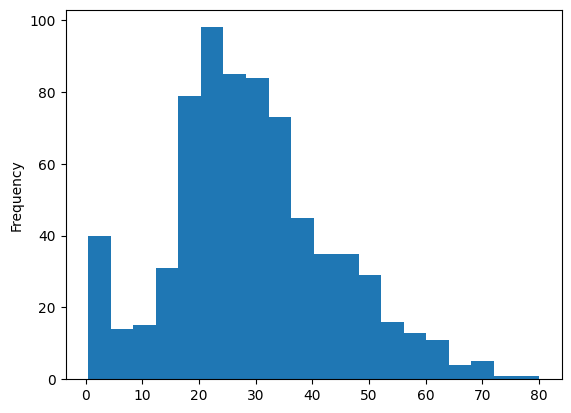

In [ ]:
df['Age'].plot(kind='hist')

<Axes: ylabel='Density'>

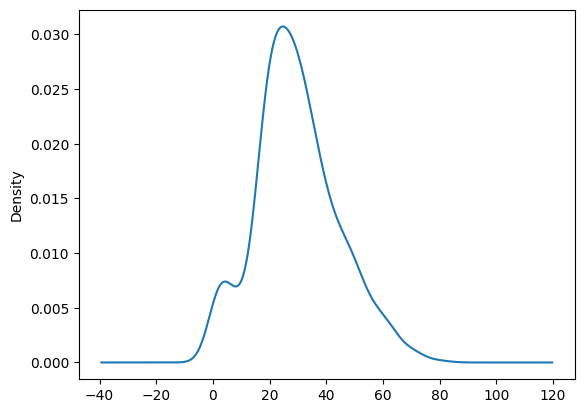

In [ ]:
df['Age'].plot(kind='kde') #skeness shape


In [11]:
df['Age'].skew()
''' 0 - perfectly normal distribution
    pos - positive skewed data
    neg - neg
'''

' 0 - perfectly normal distribution\n    pos - positive skewed data\n    neg - neg\n'

<Axes: >

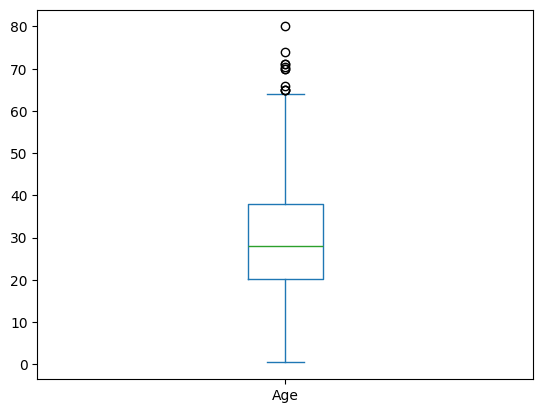

In [12]:
df['Age'].plot(kind='box')

In [ ]:
#detect whether outlier or not
df[df['Age'] > 65]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S


In [15]:
df['Age'].isnull().sum()
df['Age'].isnull().sum()/len(df['Age'])

np.float64(0.19865319865319866)

Fare
conclusion
- The data is highly(positivly) skewed
- Fare col actually contains the group fare and not the individual fare
(This might be and issue)
-We need to feature engineer new col called individual fare

In [16]:
df['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

<Axes: ylabel='Frequency'>

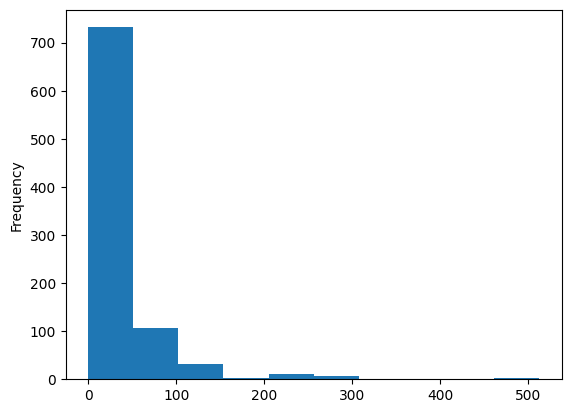

In [17]:
df['Fare'].plot(kind='hist')

<Axes: ylabel='Density'>

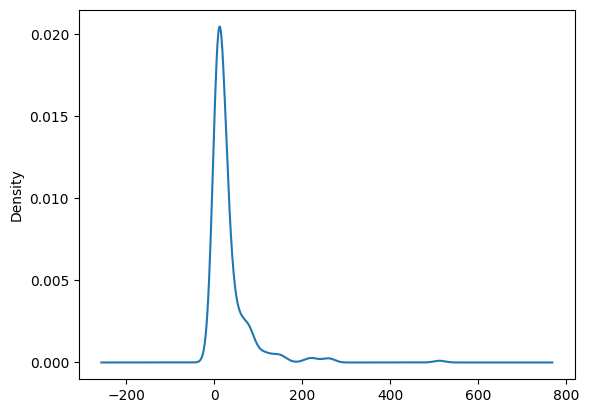

In [18]:
df['Fare'].plot(kind='kde')

In [19]:
df['Fare'].skew()

np.float64(4.787316519674893)

<Axes: >

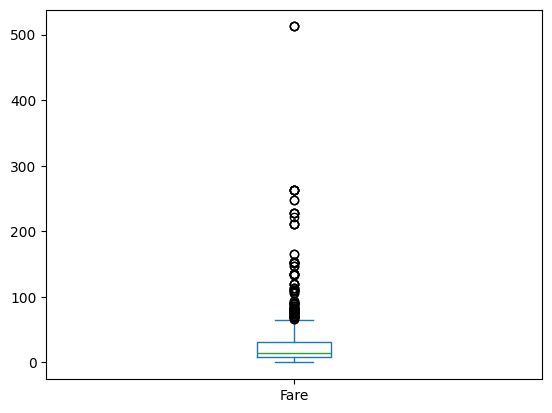

In [20]:
df['Fare'].plot(kind='box')

In [23]:
df[df['Fare'] > 250]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
311,312,1,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,19950,263.0000,C23 C25 C27,S
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
742,743,1,1,"Ryerson, Miss. Susan Parker ""Suzette""",female,21.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C


In [24]:
df['Fare'].isnull().sum()

np.int64(0)

In [ ]:
Univariate Analysis on categorical 
Descriptive Statistics : Compute the frequency distribution of the categorical 
visualization : count plot and pie chart
missing value :


Survived
conclusions
Parch and SibSp(sibling spouse) cols can be merged to form a new col call family_size
create a new col called is_alone

In [26]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: xlabel='Survived'>

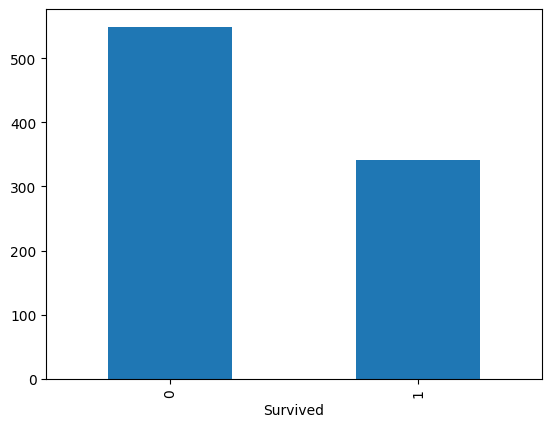

In [27]:
df['Survived'].value_counts().plot(kind='bar')

<Axes: >

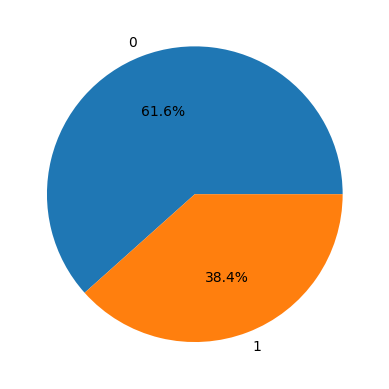

In [ ]:
df['Survived'].value_counts().plot(kind='pie',autopct='%0.1f%%')#%0.1f float number 1 digit after decimal # %% actual % symbol

In [ ]:
df['Survived'].isnull().sum()

Pclass
Conclusion
surprisingly less people travel in Pclass 2 and more people travel in Pclass 3

In [31]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [33]:
df['Sex'].value_counts()
df['Sex'].isnull().sum()

np.int64(0)

SibSp
conclusion
single traveler more

In [35]:
df['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

Parch
conclusion
single traveler more

In [ ]:
df['Parch'].value_counts()

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

In [40]:
df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

mixed col
we need to do feature engineering to understand univariate Analysis

Steps of doing Bivariate Analysis
choose two cols
1. Numerical - numerical
-you can plot graph like scatterplot(regression plots),2D histplot,2D KDEplots
-check correlation coefficient to check linear relationship
2. Numerical - Categorical
-create visualizations that compare the distribution of the numerical data across different categorcal of the categorical data
- barplot,kdplot violinplot
3. Categorical - Categorical
you can create cross-tabulations or contingency tables that show the distribution of values in one categorical columns grouped by the value 
you can plot like heatmap,stacked barplots,treemaps

conclusions

two categorical col
survived and pclass
contingency table 
conclusion


In [44]:
#contingency table
pd.crosstab(df['Survived'],df['Pclass'])
#percentage
pd.crosstab(df['Survived'],df['Pclass'],normalize='columns')
pd.crosstab(df['Survived'],df['Pclass'],normalize='columns')*100

Pclass,1,2,3
Survived,,,
0,37.037037,52.717391,75.763747
1,62.962963,47.282609,24.236253


Bivariate for
Survived and sex

In [47]:
pd.crosstab(df['Survived'],df['Sex'],normalize='columns')*100

Sex,female,male
Survived,,
0,25.796178,81.109185
1,74.203822,18.890815


In [48]:
pd.crosstab(df['Survived'],df['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Survived,,,
0,44.642857,61.038961,66.304348
1,55.357143,38.961039,33.695652


In [50]:
pd.crosstab(df['Pclass'],df['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Pclass,,,
1,50.595238,2.597403,19.720497
2,10.119048,3.896104,25.465839
3,39.285714,93.506494,54.813665


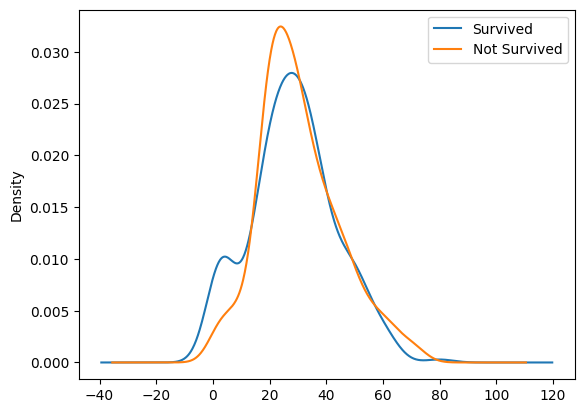

In [5]:
# survived and age
df[df['Survived']==1]['Age'].plot(kind='kde',label='Survived')
df[df['Survived']==0]['Age'].plot(kind='kde',label='Not Survived')
plt.legend()
plt.show()

In [ ]:
 # Feature Engineering on Fare col

In [6]:
df['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [9]:
df[df['Ticket'] == 'CA. 2343']
df[df['Name'].str.contains('Sage')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
641,642,1,1,"Sagesser, Mlle. Emma",female,24.0,0,0,PC 17477,69.30,B35,C
792,793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S


In [11]:
df1 = pd.read_csv('test.csv')

In [12]:
df1

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [ ]:
df = pd.concat([df,df1])


In [16]:
df['individual_fare']=df['Fare']/(df['SibSp']+df['Parch']+1)

In [19]:
df[['individual_fare','Fare']].describe()

,individual_fare,Fare
count,1308.000000,1308.000000
mean,20.518215,33.295479
std,35.774337,51.758668
min,0.000000,0.000000
25%,7.452767,7.895800
50%,8.512483,14.454200
75%,24.237500,31.275000
max,512.329200,512.329200


In [20]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,individual_fare
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.625000
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.641650
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.925000
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.550000
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.050000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S,8.050000
414,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C,108.900000
415,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S,7.250000
416,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S,8.050000


In [21]:
df['Family_size'] = df['SibSp'] + df['Parch'] + 1

In [23]:
# family_type
# 1 -> alone 2-4 -> small  >5 -> large 
def transform_family_size(num):
    if num == 1:
        return 'alone'
    elif num>1 and num <5:
        return 'small fam'
    else:
        return 'large fam'

In [26]:
df['family_type'] = df['Family_size'].apply(transform_family_size)

In [27]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,individual_fare,Family_size,family_type
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.625000,2,small fam
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.641650,2,small fam
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.925000,1,alone
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.550000,2,small fam
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.050000,1,alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S,8.050000,1,alone
414,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C,108.900000,1,alone
415,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S,7.250000,1,alone
416,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S,8.050000,1,alone


In [33]:
pd.crosstab(df['Survived'], df['family_type'], normalize='columns') * 100

family_type,alone,large fam,small fam
Survived,,,
0.0,69.646182,83.870968,42.123288
1.0,30.353818,16.129032,57.876712


In [36]:
df['surname']=df['Name'].str.split(',').str.get(0)

In [40]:
df['title'] = df['Name'].str.split(',').str.get(1).str.strip().str.split(' ').str.get(0)

In [41]:
df['title'].value_counts()

title
Mr.          757
Miss.        260
Mrs.         197
Master.       61
Rev.           8
Dr.            8
Col.           4
Ms.            2
Major.         2
Mlle.          2
Don.           1
Mme.           1
Lady.          1
Sir.           1
Capt.          1
the            1
Jonkheer.      1
Dona.          1
Name: count, dtype: int64

In [43]:
df['title'].replace(['Rev.','Dr.','Col.','Major.','Don','Capt','the','Jonkheer.',],'other',inplace=True)
temp_df = df[df['title'].isin(['Mr.','Miss.','Mrs.','Master.','other','Dona.'])]

C:\Users\hp\AppData\Local\Temp\ipykernel_14300\2335905957.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['title'].replace(['Rev.','Dr.','Col.','Major.','Don','Capt','the','Jonkheer.',],'other',inplace=True)


In [44]:
pd.crosstab(temp_df['Survived'],temp_df['title'],normalize='columns')*100

title,Master.,Miss.,Mr.,Mrs.
Survived,,,,
0.0,42.5,30.21978,84.332689,20.8
1.0,57.5,69.78022,15.667311,79.2


In [ ]:
df['Cabin'].isnull().sum ()
df['Cabin'].isnull().sum()/len(df['Cabin'])

np.float64(0.774637127578304)

In [ ]:
df['Cabin'].fillna('M',inplace=True)

Cabin
C23 C25 C27        6
G6                 5
B57 B59 B63 B66    5
F33                4
F2                 4
                  ..
C39                1
B24                1
D40                1
D38                1
C105               1
Name: count, Length: 186, dtype: int64

In [ ]:
df['dock'] = df['Cabin'].str[0]


In [54]:
df['dock'].value_counts()

dock
C    94
B    65
D    46
E    41
A    22
F    21
G     5
T     1
Name: count, dtype: int64

In [55]:
pd.crosstab(df['Pclass'],df['dock'])
pd.crosstab(df['dock'],df['Pclass'])


Pclass,1,2,3
dock,,,
A,22,0,0
B,65,0,0
C,94,0,0
D,40,6,0
E,34,4,3
F,0,13,8
G,0,0,5
T,1,0,0


<Axes: xlabel='dock'>

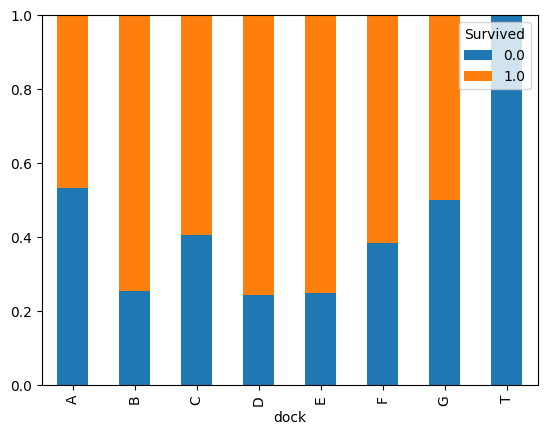

In [57]:
pd.crosstab(df['dock'],df['Survived'],normalize='index').plot(kind='bar',stacked=True)